In [2]:
%pip install seaborn


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pandas matplotlib seaborn mlflow scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load the dataset
dataset = load_breast_cancer(as_frame=True)

data = dataset.frame.copy()

# Set 1 = malignant and 0 = benign
data["malignant"] = (data["target"] == 0).astype(int)

# Remove the original target column
data = data.drop(columns=["target"])

# Inspect the dataset
print("Dataset shape:", data.shape)
print("\nFirst five rows:")
display(data.head())

print("\nMissing values:", data.isnull().sum().sum())
print("\nClass distribution:")
print(data["malignant"].value_counts())


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Missing values: 0

Class distribution:
malignant
0    357
1    212
Name: count, dtype: int64


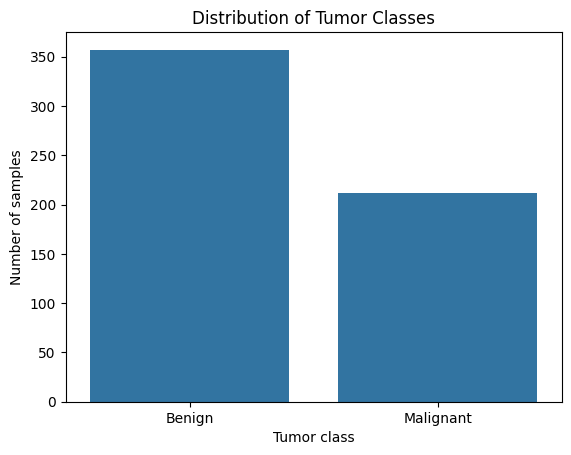

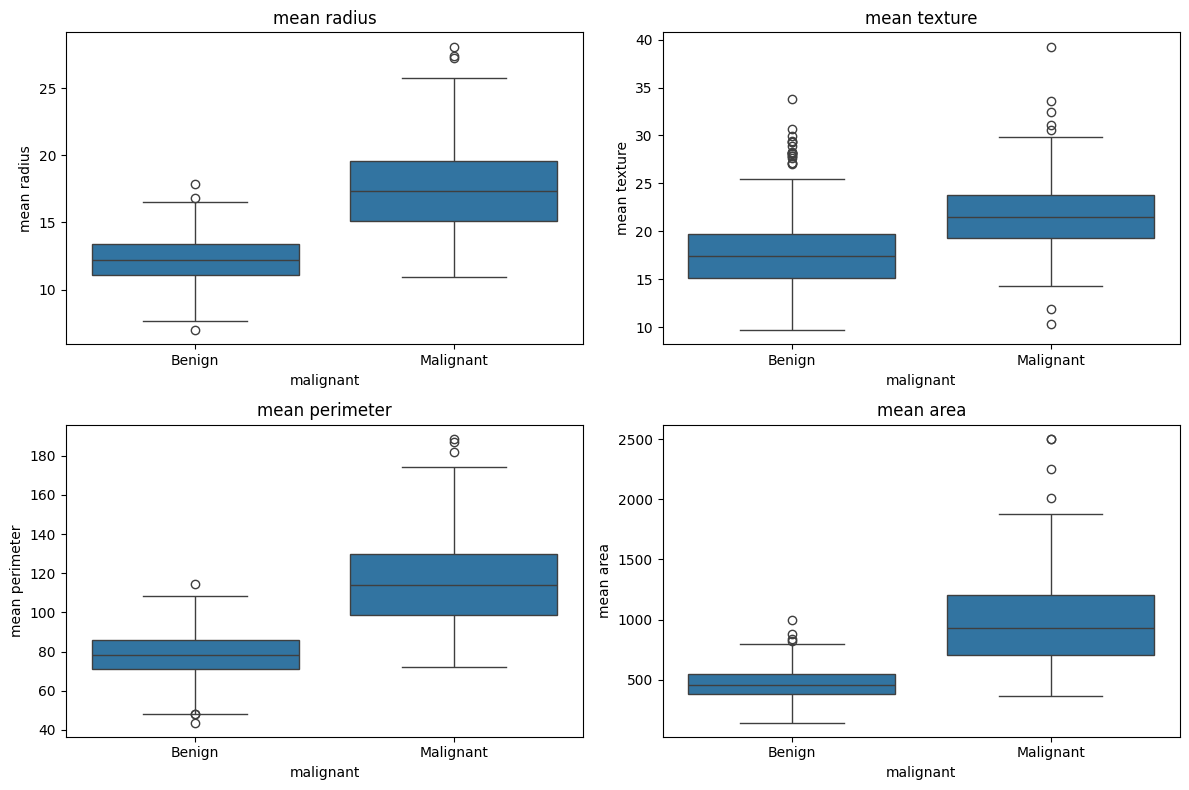

In [5]:
# Plot the distribution of the target classes
sns.countplot(data=data, x="malignant")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.title("Distribution of Tumor Classes")
plt.xlabel("Tumor class")
plt.ylabel("Number of samples")
plt.show()

features_to_plot = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.boxplot(data=data, x="malignant", y=feature, ax=ax)
    ax.set_xticks([0, 1], ["Benign", "Malignant"])
    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [6]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = data.drop(columns=["malignant"])
y = data["malignant"]

# First, set aside 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)


# Split the remaining 85% into training and validation sets
# 15% of the full dataset is approximately 17.65% of this remainder
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1765,
    random_state=42,
    stratify=y_train_val
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nMalignant cases in training set:", y_train.sum())
print("Malignant cases in validation set:", y_val.sum())
print("Malignant cases in test set:", y_test.sum())


Training set: (397, 30)
Validation set: (86, 30)
Test set: (86, 30)

Malignant cases in training set: 148
Malignant cases in validation set: 32
Malignant cases in test set: 32


In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Standardize features, then train logistic regression
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

baseline_model.fit(X_train, y_train)

# Predict malignant probabilities and classes on validation data
val_probabilities = baseline_model.predict_proba(X_val)[:, 1]
val_predictions = baseline_model.predict(X_val)

# Evaluate the baseline model
baseline_metrics = {
    "accuracy": accuracy_score(y_val, val_predictions),
    "precision": precision_score(y_val, val_predictions, zero_division=0),
    "recall": recall_score(y_val, val_predictions, zero_division=0),
    "f1_score": f1_score(y_val, val_predictions, zero_division=0),
    "roc_auc": roc_auc_score(y_val, val_probabilities)
}

print("Baseline Logistic Regression — Validation Results")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions))


Baseline Logistic Regression — Validation Results
accuracy: 0.9767
precision: 0.9688
recall: 0.9688
f1_score: 0.9688
roc_auc: 0.9988

Classification report:
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98        54
   Malignant       0.97      0.97      0.97        32

    accuracy                           0.98        86
   macro avg       0.98      0.98      0.98        86
weighted avg       0.98      0.98      0.98        86

Confusion matrix:
[[53  1]
 [ 1 31]]


In [8]:

import mlflow
from mlflow.models import infer_signature

# Create a named experiment for this project
mlflow.set_experiment("Breast_Cancer_Classification")

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("scaler", "StandardScaler")
    mlflow.log_param("max_iter", 5000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("dataset", "Wisconsin Diagnostic Breast Cancer")
    mlflow.log_param("training_rows", len(X_train))
    mlflow.log_param("validation_rows", len(X_val))
    mlflow.log_param("test_rows", len(X_test))

    mlflow.log_metrics(baseline_metrics)

    signature = infer_signature(
        X_train,
        baseline_model.predict(X_train)
    )

    mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="logistic_regression_model",
        signature=signature,
        input_example=X_train.head(5)
    )

    
    # mlflow.sklearn.log_model(
    #     sk_model=baseline_model,
    #     name="logistic_regression_model",
    #     signature=signature,
    #     input_example=X_train.head(5),
    #     skops_trusted_types=["sklearn.tree._tree.Tree"]
    # )


    print("MLflow run ID:", mlflow.active_run().info.run_id)

print("Baseline model and metrics logged to MLflow.")


MLflow run ID: 5d95a82e7aa64555883419cf2bb9cab9
Baseline model and metrics logged to MLflow.


In [ ]:
!mlflow ui --port 5000

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/18 13:47:25 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/18 13:47:25 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/18 13:47:25 INFO:     Uvicorn running on http://127.0.0.1:5000 (Press CTRL+C to quit)
2026/10/18 13:47:25 INFO:     Started parent process [99749]
/Users/ninaghar/Documents/DADS7305/mlflow_breast_cancer_lab/.venv/lib/python3.14/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  f

In [9]:
import mlflow

experiment = mlflow.get_experiment_by_name(
    "Breast_Cancer_Classification"
)

print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)

Experiment name: Breast_Cancer_Classification
Experiment ID: 1


In [10]:
runs = mlflow.search_runs(
    experiment_names=["Breast_Cancer_Classification"]
)

print("Number of runs:", len(runs))

if not runs.empty:
    display(
        runs[
            [
                "run_id",
                "status",
                "metrics.accuracy",
                "metrics.precision",
                "metrics.recall",
                "metrics.f1_score",
                "metrics.roc_auc"
            ]
        ]
    )
else:
    print("No runs found yet. Check that the baseline MLflow cell completed.")

Number of runs: 16


,run_id,status,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
0,5d95a82e7aa64555883419cf2bb9cab9,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
1,918ded99181d40c3b9ca746130a8d12a,FINISHED,NaN,NaN,NaN,NaN,NaN
2,6cd6584b90bc4f87a8fb43f5455e98db,FINISHED,NaN,NaN,NaN,NaN,NaN
3,f0c8f53254fb4b26a93bb1ce66f78c20,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
4,2e1ee13aaa064a2da14bd60e5a1417fc,FINISHED,0.965116,0.967742,0.93750,0.952381,0.996528
5,3e716e817eea4cdba9945680f419833e,FINISHED,0.953488,0.966667,0.90625,0.935484,0.997106
6,a4829ac2e66d4272af5ff6b98e75d1d0,FAILED,0.953488,0.966667,0.90625,0.935484,0.997106
7,ec5c2e3e71cf4365a383b52c21d600cc,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
8,af52ea2769af4eea910352587a4771fc,FAILED,0.976744,0.968750,0.96875,0.968750,0.998843
9,28e6f3b82c29499ea7acc318d963a673,FAILED,0.976744,0.968750,0.96875,0.968750,0.998843


In [11]:

import mlflow
import mlflow.sklearn

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from mlflow.models import infer_signature

mlflow.set_experiment("Breast_Cancer_Classification")

models = {
    "Random_Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient_Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

for model_name, model in models.items():
    with mlflow.start_run(run_name=model_name):
        # Train on the training set
        model.fit(X_train, y_train)

        # Evaluate on the validation set
        val_predictions = model.predict(X_val)
        val_probabilities = model.predict_proba(X_val)[:, 1]

        metrics = {
            "accuracy": accuracy_score(y_val, val_predictions),
            "precision": precision_score(
                y_val, val_predictions, zero_division=0
            ),
            "recall": recall_score(
                y_val, val_predictions, zero_division=0
            ),
            "f1_score": f1_score(
                y_val, val_predictions, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_val, val_probabilities)
        }

        # Log parameters and metrics
        mlflow.log_param("model_type", model_name)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("training_rows", len(X_train))
        mlflow.log_metrics(metrics)

        # Log the trained model
        signature = infer_signature(X_train, model.predict(X_train))

        # mlflow.sklearn.log_model(
        #     sk_model=model,
        #     name=f"{model_name.lower()}_model",
        #     signature=signature,
        #     input_example=X_train.head(5)
        # )


        mlflow.sklearn.log_model(
            sk_model=model,
            name=f"{model_name.lower()}_model",
            signature=signature,
            input_example=X_train.head(5),
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )

        
        print(f"\n{model_name} — Validation Results")
        for metric, value in metrics.items():
            print(f"{metric}: {value:.4f}")

print("\nBoth models have been logged to MLflow.")



Random_Forest — Validation Results
accuracy: 0.9535
precision: 0.9667
recall: 0.9062
f1_score: 0.9355
roc_auc: 0.9971

Gradient_Boosting — Validation Results
accuracy: 0.9651
precision: 0.9677
recall: 0.9375
f1_score: 0.9524
roc_auc: 0.9965

Both models have been logged to MLflow.


In [12]:

runs = mlflow.search_runs(
    experiment_names=["Breast_Cancer_Classification"]
)

comparison_columns = [
    "tags.mlflow.runName",
    "status",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.roc_auc"
]

comparison = runs[comparison_columns].sort_values(
    by="metrics.roc_auc",
    ascending=False
)

display(comparison)


,tags.mlflow.runName,status,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
2,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
5,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
9,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
10,Logistic_Regression_Baseline,FAILED,0.976744,0.968750,0.96875,0.968750,0.998843
11,Logistic_Regression_Baseline,FAILED,0.976744,0.968750,0.96875,0.968750,0.998843
13,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
15,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
17,Logistic_Regression_Baseline,FINISHED,0.976744,0.968750,0.96875,0.968750,0.998843
1,Random_Forest,FINISHED,0.953488,0.966667,0.90625,0.935484,0.997106
7,Random_Forest,FINISHED,0.953488,0.966667,0.90625,0.935484,0.997106


In [13]:

import mlflow

runs = mlflow.search_runs(
    experiment_names=["Breast_Cancer_Classification"]
)

successful_runs = runs[runs["status"] == "FINISHED"].copy()

successful_runs = successful_runs.drop_duplicates(
    subset=["tags.mlflow.runName"],
    keep="first"
)

columns = [
    "tags.mlflow.runName",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.roc_auc"
]

comparison = successful_runs[columns].sort_values(
    by="metrics.roc_auc",
    ascending=False
)

display(comparison)


,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
2,Logistic_Regression_Baseline,0.976744,0.968750,0.96875,0.968750,0.998843
1,Random_Forest,0.953488,0.966667,0.90625,0.935484,0.997106
0,Gradient_Boosting,0.965116,0.967742,0.93750,0.952381,0.996528
3,Final_Selected_Model,NaN,NaN,NaN,NaN,NaN
4,Logistic_Regression_Tuned,NaN,NaN,NaN,NaN,NaN


In [14]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean cross-validation ROC-AUC:", round(
    grid_search.best_score_, 4
))

tuned_model = grid_search.best_estimator_


Best parameters: {'classifier__C': 1}
Best mean cross-validation ROC-AUC: 0.9942


In [15]:

from mlflow.models import infer_signature

with mlflow.start_run(run_name="Logistic_Regression_Tuned"):
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("best_C", grid_search.best_params_["classifier__C"])
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("tuning_metric", "roc_auc")
    mlflow.log_metric("best_cv_roc_auc", grid_search.best_score_)

    signature = infer_signature(
        X_train,
        tuned_model.predict(X_train)
    )

    mlflow.sklearn.log_model(
        sk_model=tuned_model,
        name="tuned_logistic_regression",
        signature=signature,
        input_example=X_train.head(5)
    )

print("Tuned model logged to MLflow.")


Tuned model logged to MLflow.


In [16]:

print("Baseline validation ROC-AUC:", round(baseline_metrics["roc_auc"], 4))
print("Tuned model mean CV ROC-AUC:", round(grid_search.best_score_, 4))
print("Best parameter:", grid_search.best_params_)


Baseline validation ROC-AUC: 0.9988
Tuned model mean CV ROC-AUC: 0.9942
Best parameter: {'classifier__C': 1}


In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

candidates = {
    "Logistic_Regression_Baseline": baseline_model,
    "Random_Forest": models["Random_Forest"],
    "Gradient_Boosting": models["Gradient_Boosting"],
    "Logistic_Regression_Tuned": tuned_model
}

validation_results = []

for name, model in candidates.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    validation_results.append({
        "model": name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, probabilities)
    })

validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.sort_values(
    by="roc_auc", ascending=False
)

display(validation_comparison)

best_model_name = validation_comparison.iloc[0]["model"]
print("Selected candidate:", best_model_name)


,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic_Regression_Baseline,0.976744,0.968750,0.96875,0.968750,0.998843
3,Logistic_Regression_Tuned,0.976744,0.968750,0.96875,0.968750,0.998843
1,Random_Forest,0.953488,0.966667,0.90625,0.935484,0.997106
2,Gradient_Boosting,0.965116,0.967742,0.93750,0.952381,0.996528


Selected candidate: Logistic_Regression_Baseline


In [18]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix, classification_report

# Select the best candidate based on validation ROC-AUC
final_model = clone(candidates[best_model_name])

# Combine training and validation data for final training
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

final_model.fit(X_train_final, y_train_final)

# Evaluate once on the held-out test set
test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "test_accuracy": accuracy_score(y_test, test_predictions),
    "test_precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "test_recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "test_f1_score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "test_roc_auc": roc_auc_score(y_test, test_probabilities)
}

print("Selected model:", best_model_name)
print("\nFinal test results:")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Selected model: Logistic_Regression_Baseline

Final test results:
test_accuracy: 0.9884
test_precision: 1.0000
test_recall: 0.9688
test_f1_score: 0.9841
test_roc_auc: 1.0000

Confusion matrix:
[[54  0]
 [ 1 31]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



In [19]:

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

with mlflow.start_run(run_name="Final_Selected_Model") as run:
    mlflow.log_param("selected_model", best_model_name)
    mlflow.log_param("selection_metric", "validation_roc_auc")
    mlflow.log_param("training_rows_final", len(X_train_final))
    mlflow.log_param("test_rows", len(X_test))

    mlflow.log_metrics(test_metrics)

    signature = infer_signature(
        X_train_final,
        final_model.predict(X_train_final)
    )

    mlflow.sklearn.log_model(
        sk_model=final_model,
        name="final_model",
        signature=signature,
        input_example=X_train_final.head(5),
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

    final_run_id = run.info.run_id

print("Final MLflow run ID:", final_run_id)
print("Final model logged successfully.")


Final MLflow run ID: b904127a802e483eaf09d3dca95bc780
Final model logged successfully.


In [20]:

model_uri = f"runs:/{final_run_id}/final_model"
registered_model_name = "BreastCancerClassifier"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name=registered_model_name
)

print("Registered model:", registered_model.name)
print("Model version:", registered_model.version)


Registered model 'BreastCancerClassifier' already exists. Creating a new version of this model...
2026/10/18 14:55:20 WARNING mlflow.tracking._model_registry.fluent: Run with id b904127a802e483eaf09d3dca95bc780 has no artifacts at artifact path 'final_model', registering model based on models:/m-1b03118fc2984e69ae336a3268216dde instead


Registered model: BreastCancerClassifier
Model version: 2


Created version '2' of model 'BreastCancerClassifier'.


In [21]:

loaded_model = mlflow.sklearn.load_model(
    f"models:/{registered_model_name}/{registered_model.version}"
)

sample = X_test.head(5)

sample_predictions = loaded_model.predict(sample)
sample_probabilities = loaded_model.predict_proba(sample)[:, 1]

inference_results = sample.copy()
inference_results["actual_malignant"] = y_test.loc[sample.index]
inference_results["predicted_malignant"] = sample_predictions
inference_results["malignant_probability"] = sample_probabilities

display(inference_results[
    [
        "actual_malignant",
        "predicted_malignant",
        "malignant_probability"
    ]
])


,actual_malignant,predicted_malignant,malignant_probability
420,0,0,0.005683
548,0,0,0.000190
371,0,0,0.001670
503,1,1,1.000000
418,0,0,0.000584


In [22]:

import pandas as pd

# Select 20 examples for batch inference
batch_data = X_test.head(20).copy()

# Predict using the registered MLflow model
batch_predictions = loaded_model.predict(batch_data)
batch_probabilities = loaded_model.predict_proba(batch_data)[:, 1]

# Create a results table
batch_results = pd.DataFrame({
    "actual_malignant": y_test.loc[batch_data.index],
    "predicted_malignant": batch_predictions,
    "malignant_probability": batch_probabilities
}, index=batch_data.index)

batch_results["prediction_label"] = batch_results[
    "predicted_malignant"
].map({0: "Benign", 1: "Malignant"})

# Save predictions
batch_results.to_csv("breast_cancer_batch_predictions.csv", index=True)

display(batch_results)

print("Batch inference completed.")
print("Saved to breast_cancer_batch_predictions.csv")


,actual_malignant,predicted_malignant,malignant_probability,prediction_label
420,0,0,0.005683,Benign
548,0,0,0.000190,Benign
371,0,0,0.001670,Benign
503,1,1,1.000000,Malignant
418,0,0,0.000584,Benign
534,0,0,0.000419,Benign
7,1,1,0.969244,Malignant
123,0,0,0.030930,Benign
325,0,0,0.001739,Benign
464,0,0,0.010626,Benign


Batch inference completed.
Saved to breast_cancer_batch_predictions.csv


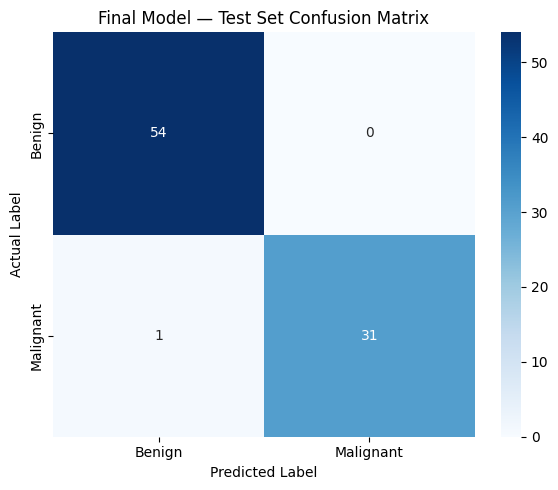

In [23]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Final Model — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig("breast_cancer_confusion_matrix.png", dpi=300)
plt.show()


,feature,importance
10,radius error,1.223454
21,worst texture,1.203346
28,worst symmetry,1.010975
15,compactness error,0.981849
20,worst radius,0.978812
23,worst area,0.946954
13,area error,0.927604
7,mean concave points,0.925782
6,mean concavity,0.921308
26,worst concavity,0.863717


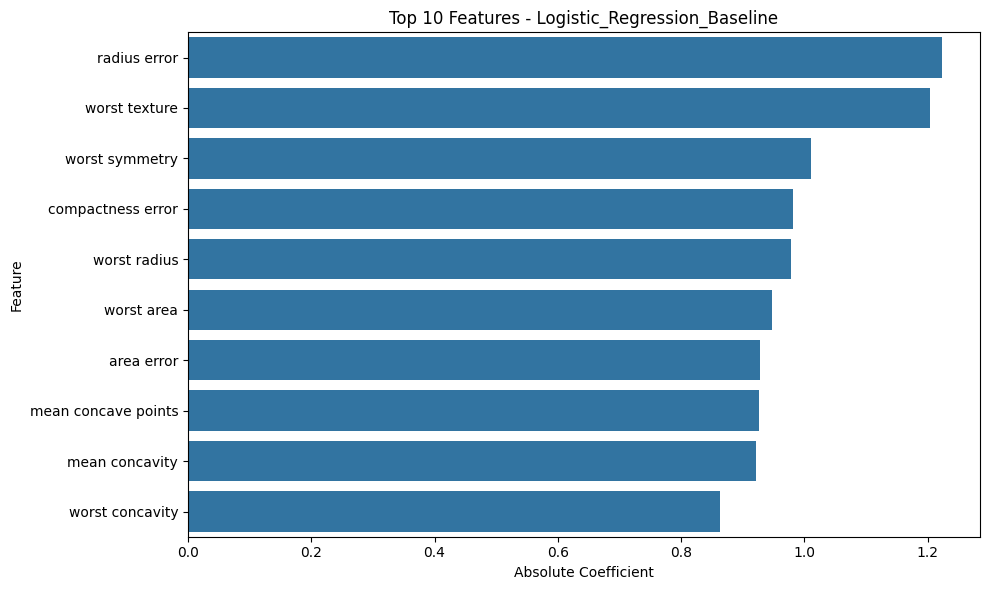

Feature importance visualization saved successfully!


In [24]:

# import numpy as np

# # Get feature importance or coefficient magnitudes
# if hasattr(final_model, "feature_importances_"):
#     importance = final_model.feature_importances_

# elif hasattr(final_model, "named_steps"):
#     classifier = final_model.named_steps["classifier"]
#     importance = np.abs(classifier.coef_[0])

# else:
#     raise ValueError("Unsupported model type for this visualization")

# feature_importance = pd.DataFrame({
#     "feature": X_train.columns,
#     "importance": importance
# }).sort_values("importance", ascending=False)

# plt.figure(figsize=(10, 6))

# sns.barplot(
#     data=feature_importance.head(10),
#     x="importance",
#     y="feature"
# )

# plt.title("Top 10 Most Influential Features")
# plt.xlabel("Importance / Absolute Standardized Coefficient")
# plt.ylabel("Feature")
# plt.tight_layout()

# plt.savefig("breast_cancer_feature_importance.png", dpi=300)
# plt.show()


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the classifier if the model is a pipeline
if hasattr(final_model, "steps"):
    classifier = final_model.steps[-1][1]
else:
    classifier = final_model

# Calculate feature importance
if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_
    importance_type = "Feature Importance"

elif hasattr(classifier, "coef_"):
    importance = np.abs(classifier.coef_[0])
    importance_type = "Absolute Coefficient"

else:
    raise ValueError(
        "This model does not support built-in feature importance."
    )

# Create a feature importance DataFrame
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": importance
}).sort_values(
    by="importance",
    ascending=False
)

# Display top 10 features
display(feature_importance.head(10))

# Plot top 10 features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="importance",
    y="feature"
)

plt.title(f"Top 10 Features - {best_model_name}")
plt.xlabel(importance_type)
plt.ylabel("Feature")
plt.tight_layout()

# Save the visualization
plt.savefig(
    "breast_cancer_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance visualization saved successfully!")



In [25]:
print("Selected model:", best_model_name)
print("Pipeline steps:", final_model.named_steps.keys())

Selected model: Logistic_Regression_Baseline
Pipeline steps: dict_keys(['standardscaler', 'logisticregression'])


In [29]:

with mlflow.start_run(run_id=final_run_id):
    mlflow.log_artifact("breast_cancer_batch_predictions.csv")
    mlflow.log_artifact("breast_cancer_confusion_matrix.png")
    mlflow.log_artifact("breast_cancer_feature_importance.png")

print("Evaluation artifacts uploaded to MLflow.")


Evaluation artifacts uploaded to MLflow.


In [ ]:

import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()

print("Tracking URI:", mlflow.get_tracking_uri())
print("Final run ID:", final_run_id)

artifacts = client.list_artifacts(final_run_id)

print("\nArtifacts in final run:")
for artifact in artifacts:
    print(artifact.path, "| Directory:", artifact.is_dir)


In [1]:
import sys
print(sys.executable)

/Library/Frameworks/Python.framework/Versions/3.13/bin/python3.13


In [26]:

import requests

# Prepare one sample
sample = X_test.head(1)

payload = {
    "dataframe_split": {
        "columns": sample.columns.tolist(),
        "data": sample.values.tolist()
    }
}

# Send data to MLflow model server
response = requests.post(
    "http://127.0.0.1:5001/invocations",
    json=payload,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Response:", response.text)


HTTP status: 200
Response: {"predictions": [0]}
